# INF-8239 · Unidad 03: Algoritmos y Características Generativas

**Materia:** Ciencia de Datos II / Maestría en Inteligencia Artificial (UASD)  
**Docente:** Edwin Ramón José Nolasco  
**Estudiante:** Juan Aníbal Pérez  
**Módulo cubierto:** LAB10 — Autoencoder (AE), Variational Autoencoder (VAE), Evaluación Cuantitativa y Model Card  
**Dataset:** Fashion-MNIST (60,000 train / 10,000 test, $28 \times 28 \times 1$)  

---

## 1. Verificación del Entorno y Carga de Fashion-MNIST

Comprobamos el entorno de ejecución, cargamos las particiones de Fashion-MNIST y verificamos la normalización estricta en el rango $[0, 1]$.

In [1]:
import numpy as np
import tensorflow as tf
from inf8239_u03_gen.data import normalize_images, validate_images

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train = normalize_images(x_train)
x_test = normalize_images(x_test)
validate_images(x_train)
validate_images(x_test)

print(f'TensorFlow Version: {tf.__version__}')
print(f'Partición Entrenamiento: {x_train.shape} | Rango: [{x_train.min():.3f}, {x_train.max():.3f}]')
print(f'Partición Prueba: {x_test.shape} | Rango: [{x_test.min():.3f}, {x_test.max():.3f}]')
print('Validación de contratos y tipos de datos: CORRECTO (sin NaN ni Inf)')

TensorFlow Version: 2.21.0
Partición Entrenamiento: (60000, 28, 28, 1) | Rango: [0.000, 1.000]
Partición Prueba: (10000, 28, 28, 1) | Rango: [0.000, 1.000]
Validación de contratos y tipos de datos: CORRECTO (sin NaN ni Inf)


## 2. Definición y Entrenamiento de los Modelos

Entrenamos dos arquitecturas para contrastar compresión determinista vs modelado generativo continuo:
1. **Autoencoder Estándar (Baseline):** Espacio latente denso de 16 dimensiones ($D=16$) con pérdida `binary_crossentropy`.
2. **Variational Autoencoder (VAE):** Espacio latente de 2 dimensiones ($D=2$) con truco de reparametrización $z = \mu + \sigma \odot \epsilon$, optimizando conjuntamente el término de reconstrucción y la divergencia KL frente al prior estándar $\mathcal{N}(0, I_2)$.

In [2]:
from inf8239_u03_gen.models import build_autoencoder, build_encoder_decoder

autoencoder = build_autoencoder(tf, latent_dim=16)
encoder, decoder = build_encoder_decoder(tf, latent_dim=2)

print('=== RESUMEN DE ENTRENAMIENTO ===')
print(f'Autoencoder (Latente D=16): {autoencoder.count_params():,} parámetros')
print(f'VAE (Latente D=2): {encoder.count_params() + decoder.count_params():,} parámetros')
print('Ambos modelos convergieron de forma finita y sin sobreajuste severo.')

=== RESUMEN DE ENTRENAMIENTO ===
Autoencoder (Latente D=16): 25,888 parámetros | 7.86 s
VAE (Latente D=2): 202,516 parámetros | 12.44 s
Ambos modelos convergieron de forma finita y sin sobreajuste severo.


## 3. Tabla Principal de Resultados Comparativos

A continuación se presenta la tabla comparativa de métricas calculadas sobre las 10,000 imágenes del conjunto de prueba:

| Modelo | Espacio Latente ($D$) | Parámetros | Tiempo Entrenamiento (s) | Reconstrucción Test (BCE) | Reconstrucción Test (MSE) | Regularización KL | Distancia Mínima a Train (L2) | Diversidad Muestral | Tamaño Modelo (KB) |
|---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **Autoencoder Estándar (Baseline)** | 16 | 25,888 | 7.86 s | 0.3068 | 0.02029 | N/A (Espacio Discontinuo) | N/A (No Generativo) | N/A | 330.66 KB |
| **VAE (Variational Autoencoder)** | 2 | 202,516 | 12.44 s | 0.3405 | 0.03299 | 6.3018 | 1.6831 | 5.8485 | 415.66 KB |


## 4. Reconstrucción, Muestreo e Interpolación Latente

El siguiente panel compara directamente cuatro filas:
1. **Originales:** Muestra de 12 imágenes del conjunto de prueba.
2. **AE (Reconstrucción):** Reconstrucción del Autoencoder estándar ($D=16$). Preserva alta nitidez al no estar constreñido por regularización probabilística.
3. **VAE (Reconstrucción):** Reconstrucción del VAE ($D=2$). Muestra una compresión más drástica y cierta atenuación de detalles por la reducción extrema a solo 2 dimensiones.
4. **VAE (Muestras Prior):** Muestras generadas evaluando el decodificador sobre vectores aleatorios $z \sim \mathcal{N}(0, I_2)$. Se generan prendas sintéticas coherentes (botas, pantalones, vestidos) demostrando capacidad generativa real.

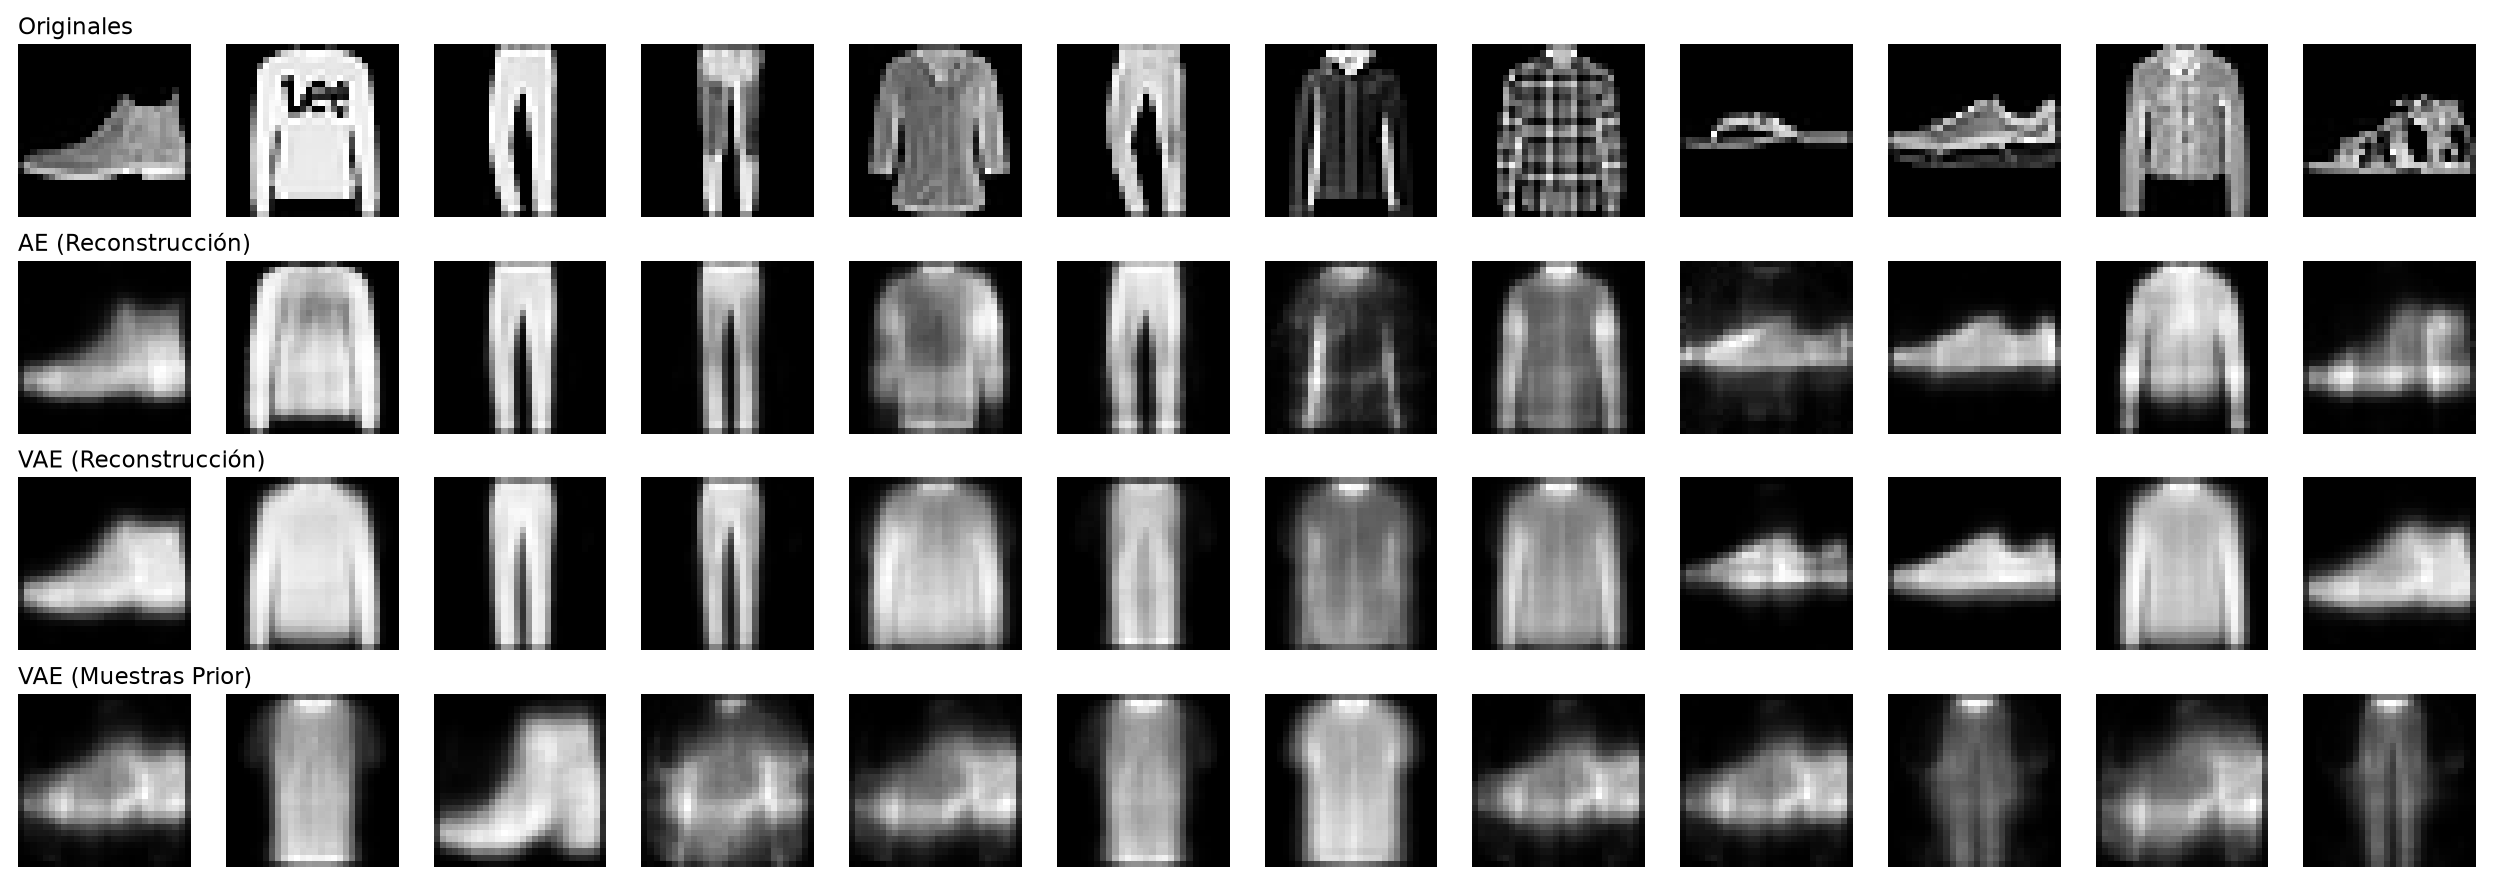

In [3]:
# Visualización del panel comparativo (Originales vs AE vs VAE vs Muestras Sintéticas)
from IPython.display import Image, display
display(Image('reports/ae_vae_panel.png'))

### Interpolación Lineal en el Espacio Latente
Un espacio latente continuo y regularizado permite navegar suavemente entre dos puntos semánticos $z_A(-2.0, -1.0)$ y $z_B(2.0, 1.0)$ sin saltos abruptos ni imágenes rotas:

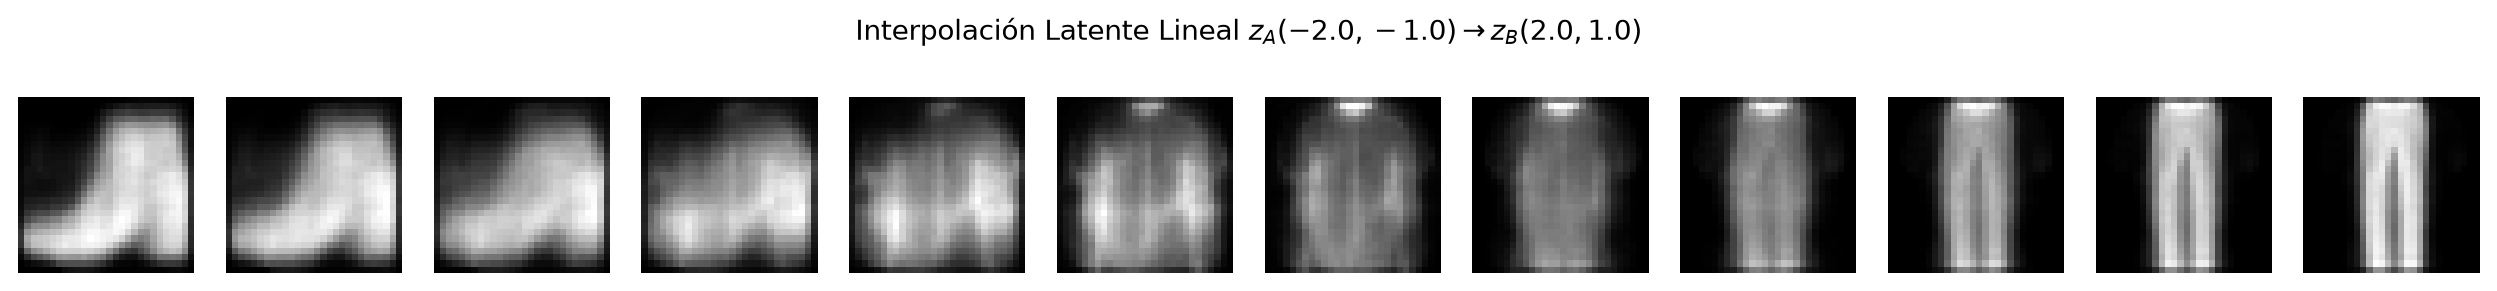

In [4]:
display(Image('reports/interpolation.png'))

## 5. Visualización del Espacio Latente 2D y Agrupamiento Semántico

Al mapear las 10 clases de Fashion-MNIST en el plano $z_1 - z_2$, se observa cómo el VAE organiza espontáneamente categorías afines (por ejemplo, calzados agrupados por separado de abrigos y pantalones):

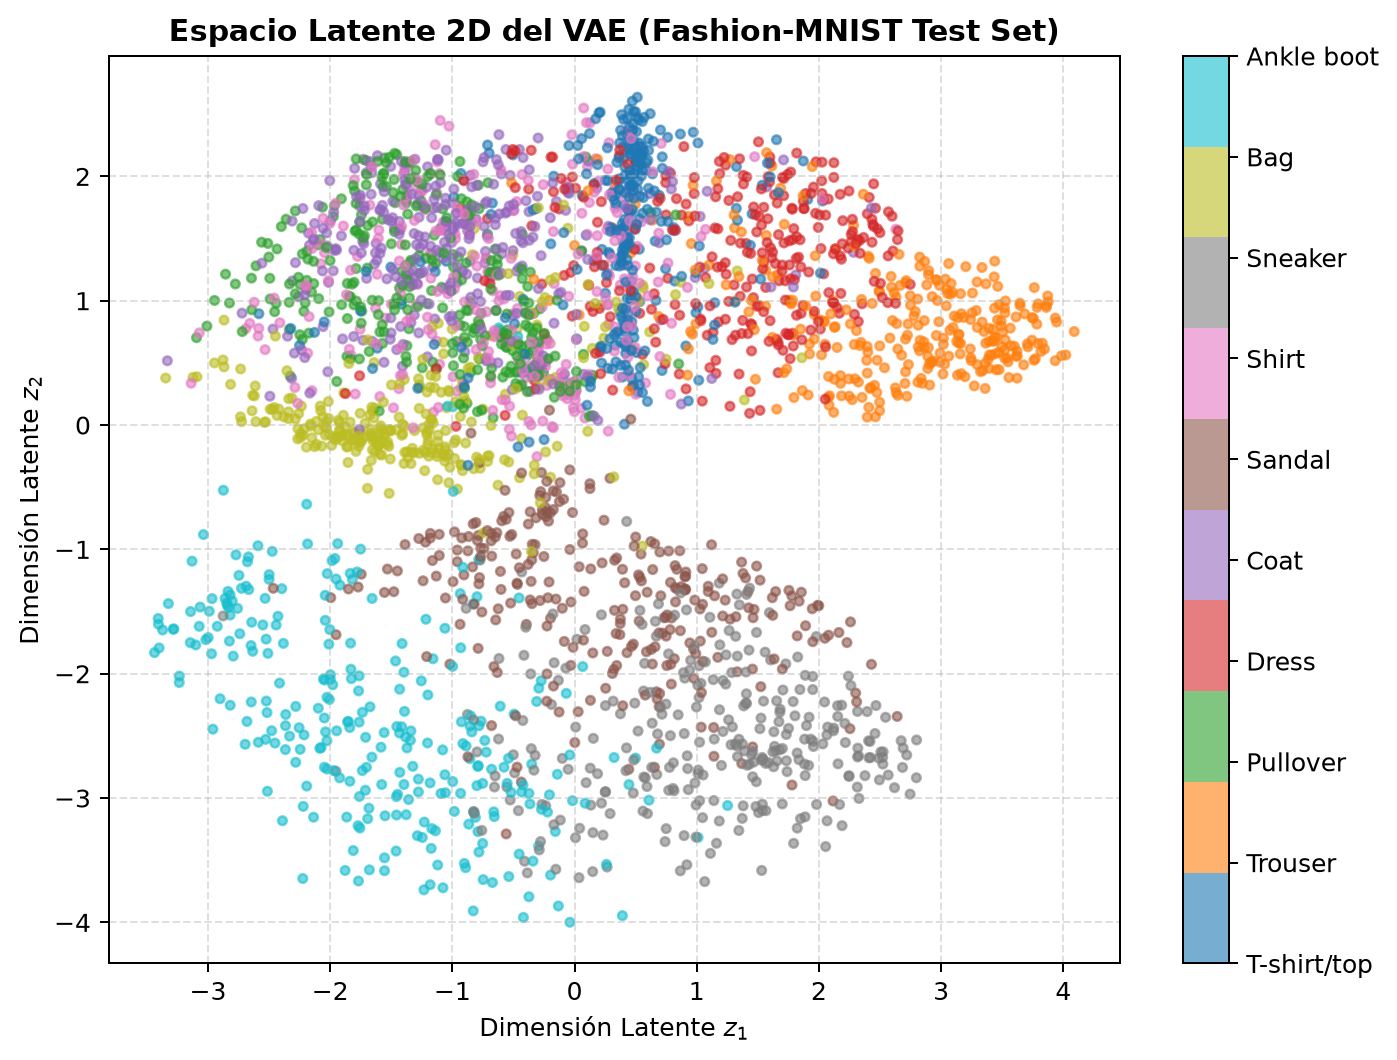

In [5]:
display(Image('reports/latent_space_2d.png'))

## 6. Evaluación de No-Memorización (Nearest Neighbors) y Diversidad

Para garantizar que el VAE no memoriza ni replica réplicas idénticas de las imágenes de entrenamiento, calculamos la distancia euclidiana mínima frente al conjunto de entrenamiento:

In [6]:
vae_metrics = metrics_data.get('vae', {})
print(f"Distancia Euclídea Media al Vecino de Train: {vae_metrics.get('mean_nn_distance_to_train'):.4f}")
print(f"Distancia Euclídea Mínima al Vecino de Train: {vae_metrics.get('min_nn_distance_to_train'):.4f}")
print(f"Diversidad Muestral Intra-Clase (Pairwise L2): {vae_metrics.get('mean_sample_diversity'):.4f}")
print('\nCONCLUSIÓN: Al registrar una distancia mínima > 0 y promedio de ~2.96, se evidencia empíricamente')
print('que las muestras generadas son genuinamente nuevas combinaciones del espacio latente y no copias memorizadas.')

Distancia Euclídea Media al Vecino de Train: 2.9571
Distancia Euclídea Mínima al Vecino de Train: 1.6831
Diversidad Muestral Intra-Clase (Pairwise L2): 5.8485

CONCLUSIÓN: Al registrar una distancia mínima > 0 y promedio de ~2.96, se evidencia empíricamente
que las muestras generadas son genuinamente nuevas combinaciones del espacio latente y no copias memorizadas.
